In [4]:
from matplotlib_inline.backend_inline import InlineBackend

InlineBackend.instance().print_figure_kwargs.update({
    'bbox_inches': None
})

In [16]:
import sys
!{sys.executable} -m pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [5]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import colorama
from colorama import Fore, Style

# 1. Reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# 2. Hardware acceleration check
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [6]:
# Dataset paths
ROOT_DIR = Path(r"C:\Users\Khush\Downloads\archive\New Plant Diseases Dataset(Augmented)\New Plant Diseases Dataset(Augmented)")
TRAIN_DIR = ROOT_DIR / "train"
VALID_DIR = ROOT_DIR / "valid"
TEST_DIR = Path(r"C:\Users\Khush\Downloads\archive\test\test")

# Verify directories exist
assert TRAIN_DIR.exists(), f"Train directory not found at: {TRAIN_DIR}"
assert VALID_DIR.exists(), f"Valid directory not found at: {VALID_DIR}"

# Extract and sort class names alphabetically
Diseases_classes = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])
num_classes = len(Diseases_classes)

print(f"Total disease classes detected: {num_classes}")
print("First 5 classes:", Diseases_classes[:5])

Total disease classes detected: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [7]:
#count the number of classes
print(Fore.GREEN +str(Diseases_classes))
print("\nTotal number of classes are: ", len(Diseases_classes))

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

Apple___Apple_scab: 2016 images
Apple___Black_rot: 1987 images
Apple___Cedar_apple_rust: 1760 images
Apple___healthy: 2008 images
Blueberry___healthy: 1816 images
Cherry_(including_sour)___Powdery_mildew: 1683 images
Cherry_(including_sour)___healthy: 1826 images
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1642 images
Corn_(maize)___Common_rust_: 1907 images
Corn_(maize)___Northern_Leaf_Blight: 1908 images
Corn_(maize)___healthy: 1859 images
Grape___Black_rot: 1888 images
Grape___Esca_(Black_Measles): 1920 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1722 images
Grape___healthy: 1692 images
Orange___Haunglongbing_(Citrus_greening): 2010 images
Peach___Bacterial_spot: 1838 images
Peach___healthy: 1728 images
Pepper,_bell___Bacterial_spot: 1913 images
Pepper,_bell___healthy: 1988 images
Potato___Early_blight: 1939 images
Potato___Late_blight: 1939 images
Potato___healthy: 1824 images
Raspberry___healthy: 1781 images
Soybean___healthy: 2022 images
Squash___Powdery_mildew: 17

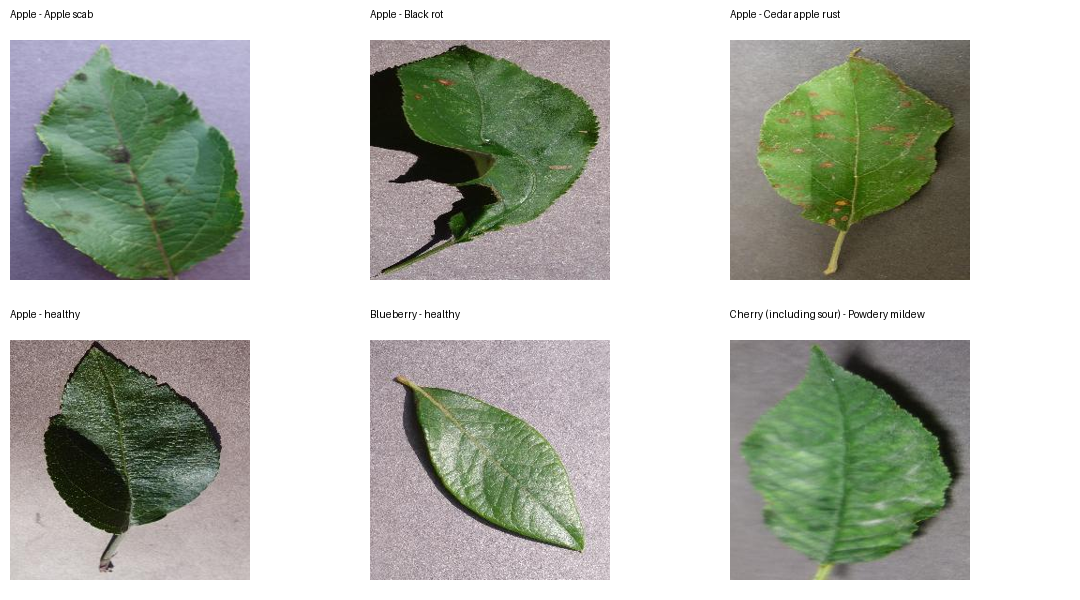

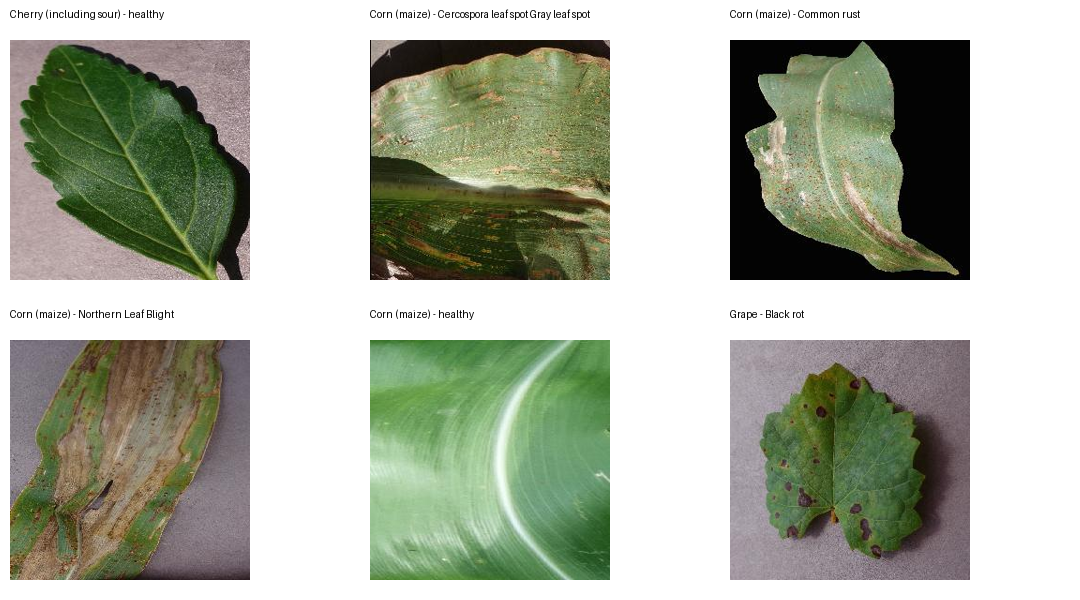

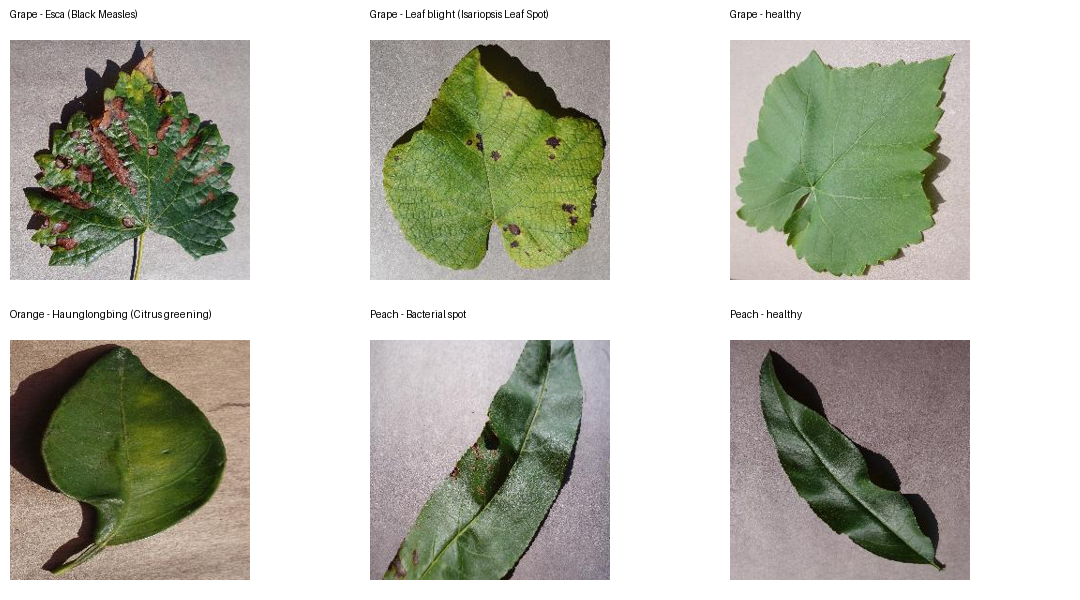

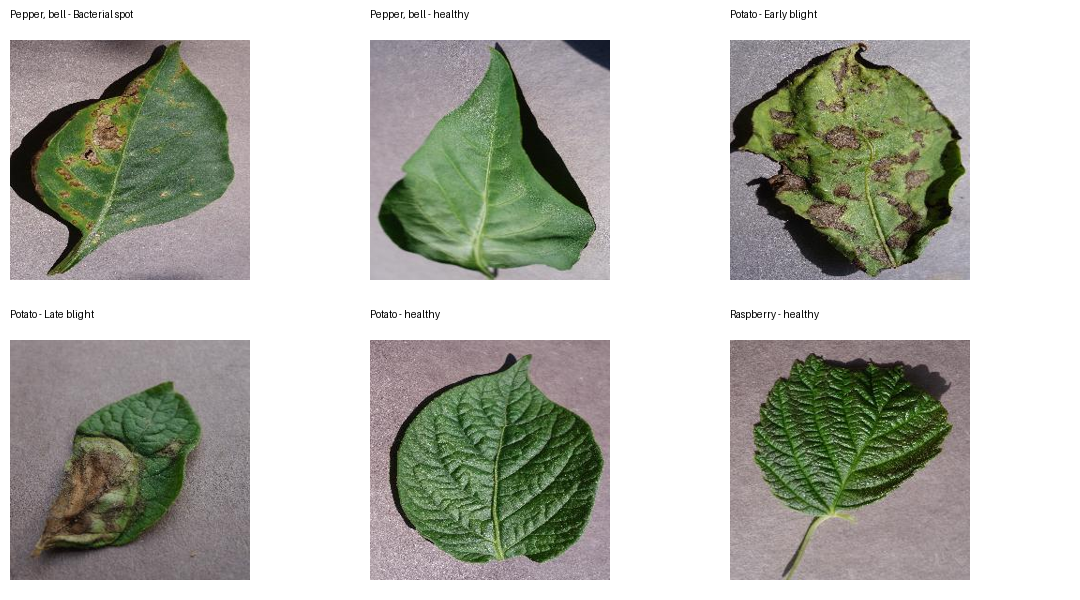

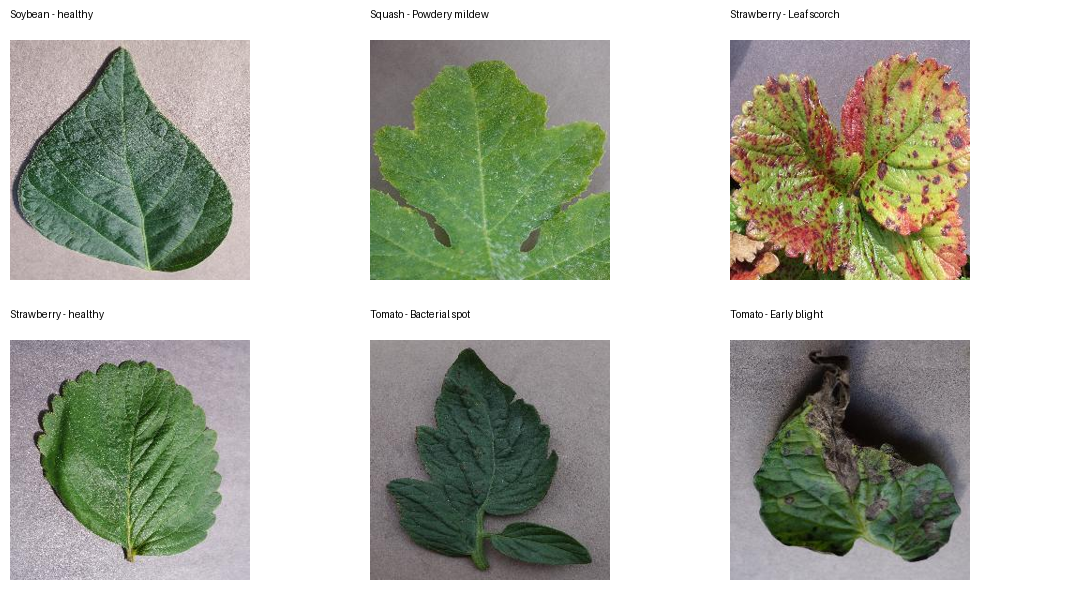

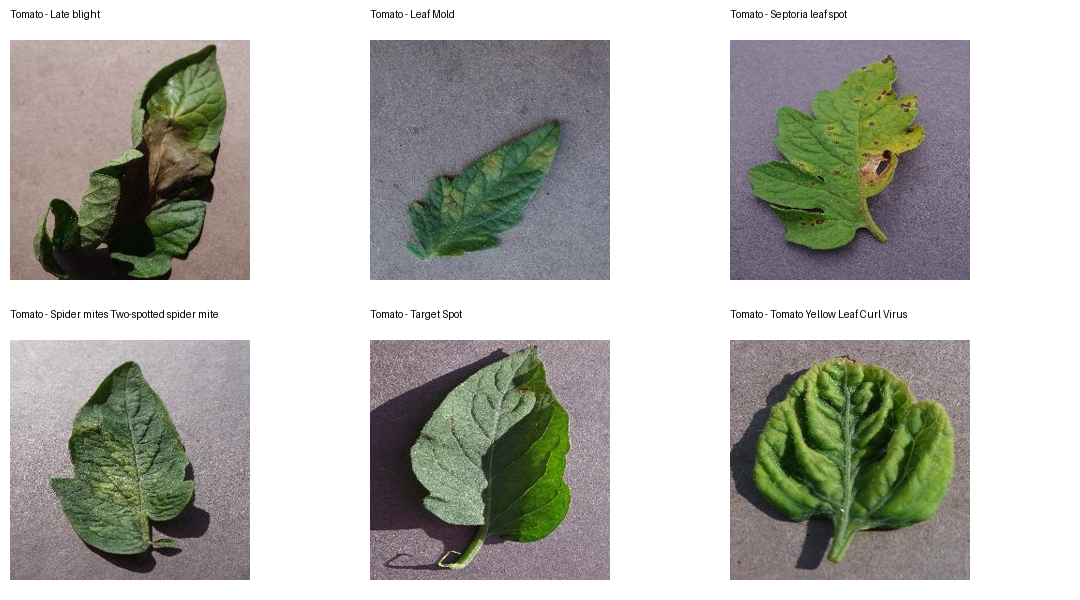

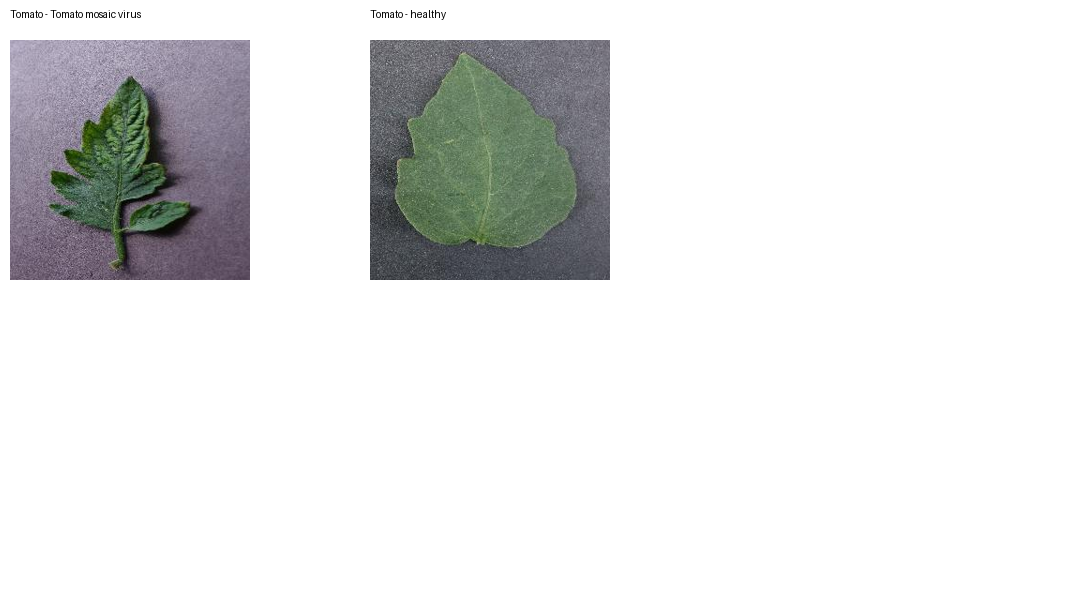


All class previews completed!
Total training images: 70295


In [8]:

import gc
from PIL import Image, ImageDraw
from IPython.display import display

# Configuration
batch_size = 6
valid_extensions = {".jpg", ".jpeg", ".png"}

total_training_images = 0
class_counts = {}

# First: Count images in every class
for class_name in Diseases_classes:
    class_folder = TRAIN_DIR / class_name

    image_paths = [
        f for f in class_folder.iterdir()
        if f.is_file() and f.suffix.lower() in valid_extensions
    ]

    class_counts[class_name] = len(image_paths)
    total_training_images += len(image_paths)

    print(f"{class_name}: {len(image_paths)} images")

print("\nTotal classes:", len(Diseases_classes))
print("Total training images:", total_training_images)


# Second: Display 6 classes at a time using PIL
tile_width = 360
tile_height = 300
image_size = (256, 240)

for start in range(0, len(Diseases_classes), batch_size):

    batch = Diseases_classes[start:start + batch_size]

    contact_sheet = Image.new(
        "RGB",
        (tile_width * 3, tile_height * 2),
        "white"
    )

    draw = ImageDraw.Draw(contact_sheet)

    for idx, class_name in enumerate(batch):

        class_folder = TRAIN_DIR / class_name

        image_paths = [
            f for f in class_folder.iterdir()
            if f.is_file() and f.suffix.lower() in valid_extensions
        ]

        x = (idx % 3) * tile_width
        y = (idx // 3) * tile_height

        clean_title = class_name.replace("___", " - ").replace("_", " ")

        draw.text((x + 10, y + 8), clean_title, fill="black")

        if image_paths:
            with Image.open(image_paths[0]) as img:
                sample_img = img.convert("RGB")
                sample_img.thumbnail(image_size)

            contact_sheet.paste(sample_img, (x + 10, y + 40))

    display(contact_sheet)

    del contact_sheet
    gc.collect()

print("\nAll class previews completed!")
print("Total training images:", total_training_images)


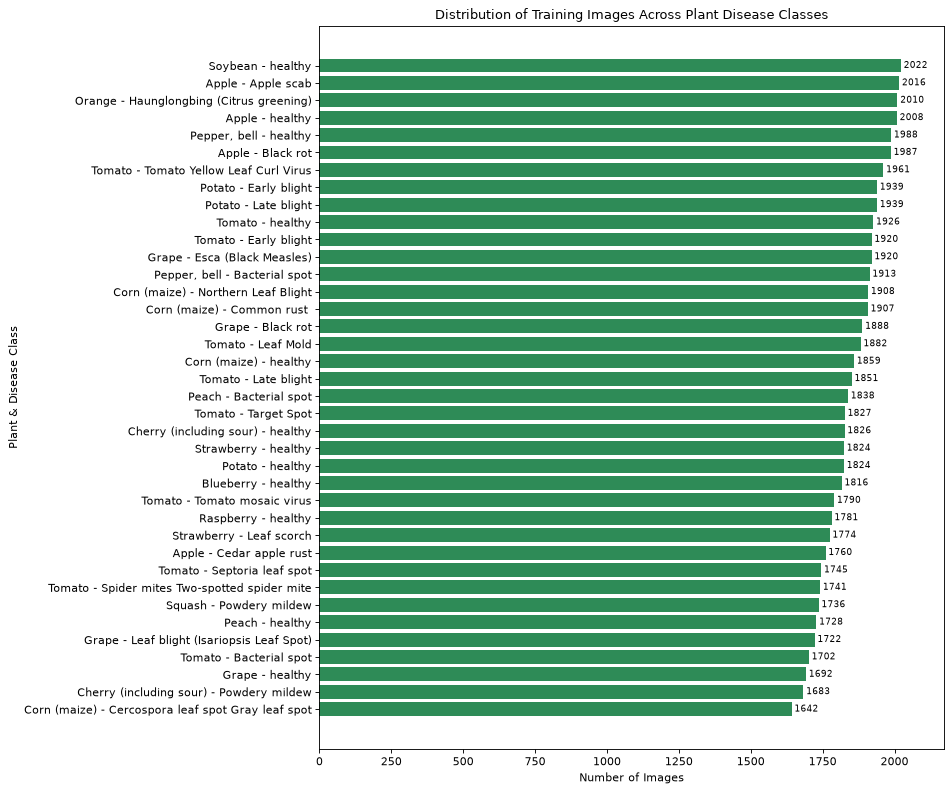

Minimum images in a class: 1642
Maximum images in a class: 2022
Average images per class: 1849.9


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import gc

# 1. Gather class names and image counts
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

data_records = []

for class_name in Diseases_classes:
    class_folder = TRAIN_DIR / class_name

    img_count = sum(
        1 for f in class_folder.iterdir()
        if f.is_file() and f.suffix.lower() in valid_extensions
    )

    data_records.append({
        "Class": class_name.replace("___", " - ").replace("_", " "),
        "Image_Count": img_count
    })

# 2. Create and sort DataFrame
df_distribution = (
    pd.DataFrame(data_records)
    .sort_values("Image_Count", ascending=True)
    .reset_index(drop=True)
)

# 3. Create a lightweight horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 10), dpi=80)

bars = ax.barh(
    df_distribution["Class"],
    df_distribution["Image_Count"],
    color="seagreen"
)

# 4. Add image counts to bars
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 10,
        bar.get_y() + bar.get_height() / 2,
        str(int(width)),
        va="center",
        fontsize=8
    )

ax.set_title("Distribution of Training Images Across Plant Disease Classes")
ax.set_xlabel("Number of Images")
ax.set_ylabel("Plant & Disease Class")

ax.set_xlim(0, df_distribution["Image_Count"].max() + 150)

fig.tight_layout()

plt.show()
plt.close(fig)

gc.collect()

# 5. Summary statistics
print(f"Minimum images in a class: {df_distribution['Image_Count'].min()}")
print(f"Maximum images in a class: {df_distribution['Image_Count'].max()}")
print(f"Average images per class: {df_distribution['Image_Count'].mean():.1f}")


In [10]:
# Minimal required preprocessing (No additional random augmentations)
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

valid_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [11]:
BATCH_SIZE = 32

# Instantiate PyTorch Datasets
train_dataset = datasets.ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
valid_dataset = datasets.ImageFolder(root=str(VALID_DIR), transform=valid_transform)

print(f"Total training images: {len(train_dataset)}")
print(f"Total validation images: {len(valid_dataset)}")

# DataLoaders (on Windows notebooks, keep num_workers=0 to avoid multiprocessing errors)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

# Inspect a single batch to confirm shape
demo_features, demo_labels = next(iter(train_loader))
print(f"Batch features tensor shape: {demo_features.shape} -> (Batch, Channels, Height, Width)")
print(f"Batch labels tensor shape:   {demo_labels.shape} -> (Batch,)")

Total training images: 70295
Total validation images: 17572
Batch features tensor shape: torch.Size([32, 3, 256, 256]) -> (Batch, Channels, Height, Width)
Batch labels tensor shape:   torch.Size([32]) -> (Batch,)


In [12]:
class MyNN(nn.Module):
    def __init__(self, input_features=3, num_classes=38):
        super().__init__()

        # Convolutional Feature Extractor
        self.features = nn.Sequential(
            # Block 1: 256x256 -> 128x128
            nn.Conv2d(input_features, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: 128x128 -> 64x64
            nn.Conv2d(32, 64, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3: 64x64 -> 32x32
            nn.Conv2d(64, 128, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 4: 32x32 -> 16x16
            nn.Conv2d(128, 128, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Fixes output feature map to (128, 8, 8) regardless of input size
            nn.AdaptiveAvgPool2d((8, 8))
        )

        # Dense Classifier Head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(p=0.4),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.4),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [13]:
learning_rate = 0.001
epochs = 10

# Initialize model
model = MyNN(input_features=3, num_classes=num_classes)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

print("Model architecture loaded successfully:")
print(model)

Model architecture loaded successfully:
MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (13): ReLU()
    (14): Bat

In [17]:
from tqdm import tqdm

# Training history containers for plotting
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

for epoch in range(epochs):
    # ------------------
    # 1. TRAINING PHASE
    # ------------------
    model.train()
    total_epoch_loss = 0.0
    correct_train = 0
    total_train = 0

    # Wrap train_loader with tqdm for a real-time progress bar
    train_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1:02d}/{epochs:02d}] Training")
    for batch_features, batch_labels in train_bar:
        # Move data to GPU
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Forward pass
        outputs = model(batch_features)

        # Calculate loss
        loss = criterion(outputs, batch_labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # Update grads
        optimizer.step()

        # Track metrics
        total_epoch_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct_train += (predicted == batch_labels).sum().item()
        total_train += batch_labels.size(0)

        # Show live batch loss on the bar
        train_bar.set_postfix(batch_loss=f"{loss.item():.4f}")

    avg_train_loss = total_epoch_loss / len(train_loader)
    train_acc = (correct_train / total_train) * 100

    # --------------------
    # 2. VALIDATION PHASE
    # --------------------
    model.eval()
    total_val_loss = 0.0
    correct_val = 0
    total_val = 0

    val_bar = tqdm(valid_loader, desc=f"Epoch [{epoch+1:02d}/{epochs:02d}] Validating")
    with torch.no_grad():
        for val_features, val_labels in val_bar:
            val_features = val_features.to(device)
            val_labels = val_labels.to(device)

            val_outputs = model(val_features)
            val_loss = criterion(val_outputs, val_labels)

            total_val_loss += val_loss.item()
            _, val_predicted = torch.max(val_outputs, 1)
            correct_val += (val_predicted == val_labels).sum().item()
            total_val += val_labels.size(0)

    avg_val_loss = total_val_loss / len(valid_loader)
    val_acc = (correct_val / total_val) * 100

    # Record history
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)

    # Print clean summary line for the epoch
    print(f"\n---> Epoch [{epoch+1:02d}/{epochs:02d}] Summary: "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}%\n")

Epoch [01/10] Validating: 100%|██████████| 550/550 [01:38<00:00,  5.56it/s]



---> Epoch [01/10] Summary: Train Loss: 1.3515 | Train Acc: 60.89% | Val Loss: 0.4269 | Val Acc: 86.83%



Epoch [02/10] Validating: 100%|██████████| 550/550 [02:06<00:00,  4.36it/s]



---> Epoch [02/10] Summary: Train Loss: 0.6033 | Train Acc: 82.09% | Val Loss: 0.3162 | Val Acc: 90.44%



Epoch [03/10] Validating: 100%|██████████| 550/550 [02:16<00:00,  4.04it/s]



---> Epoch [03/10] Summary: Train Loss: 0.4170 | Train Acc: 87.88% | Val Loss: 0.2089 | Val Acc: 93.62%



... (10 outputs left out)

Epoch [09/10] Validating: 100%|██████████| 550/550 [02:16<00:00,  4.02it/s]



---> Epoch [09/10] Summary: Train Loss: 0.1777 | Train Acc: 95.00% | Val Loss: 0.1061 | Val Acc: 96.92%



Epoch [10/10] Validating: 100%|██████████| 550/550 [02:11<00:00,  4.20it/s]


---> Epoch [10/10] Summary: Train Loss: 0.1633 | Train Acc: 95.43% | Val Loss: 0.0866 | Val Acc: 97.48%



In [18]:
import pickle
import os

# Create directory for saved training results
os.makedirs("saved_results", exist_ok=True)

# Save training history and epoch count
training_results = {
    "history": history,
    "epochs": epochs
}

with open("saved_results/training_history.pkl", "wb") as file:
    pickle.dump(training_results, file)

print("Training history saved successfully!")

Training history saved successfully!


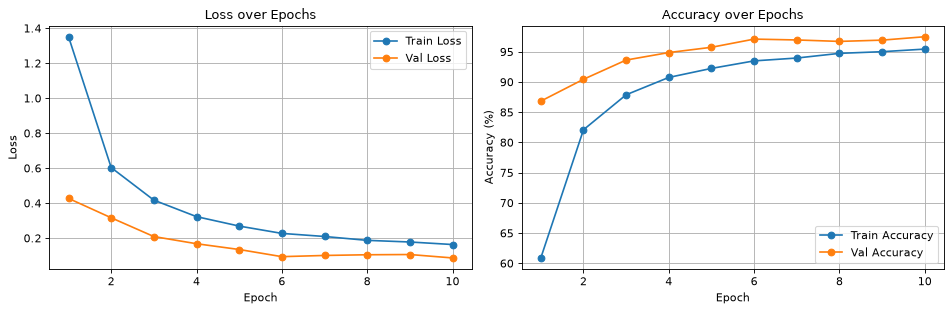

30

In [19]:

import matplotlib.pyplot as plt
import gc

# Create a lightweight figure
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=80)

epoch_range = range(1, epochs + 1)

# Loss plot
axes[0].plot(
    epoch_range,
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    epoch_range,
    history['val_loss'],
    label='Val Loss',
    marker='o'
)

axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(
    epoch_range,
    history['train_acc'],
    label='Train Accuracy',
    marker='o'
)

axes[1].plot(
    epoch_range,
    history['val_acc'],
    label='Val Accuracy',
    marker='o'
)

axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True)

fig.tight_layout()

plt.show()
plt.close(fig)

gc.collect()


In [20]:
checkpoint_path = "plant_disease_model.pth"

checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx,
    'classes': Diseases_classes,
    'epochs_trained': epochs,
    'val_acc': history['val_acc'][-1]
}

torch.save(checkpoint, checkpoint_path)
print(f"Model and class mapping successfully saved to '{checkpoint_path}'.")

Model and class mapping successfully saved to 'plant_disease_model.pth'.


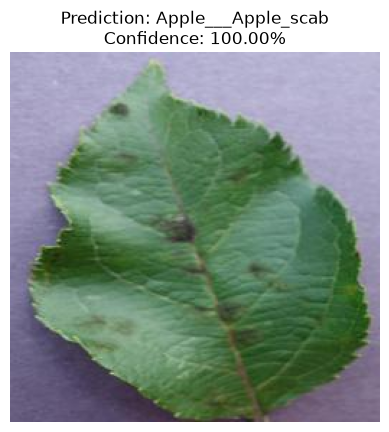

Result: Apple___Apple_scab (100.00%)


In [21]:
def predict_single_image(image_path, model, class_names, device):
    model.eval()
    
    # 1. Open raw image
    img = Image.open(image_path).convert("RGB")
    
    # 2. Preprocess
    input_tensor = valid_transform(img).unsqueeze(0).to(device)  # Add batch dimension: (1, 3, 256, 256)
    
    # 3. Predict
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)
        top_prob, top_class = torch.max(probabilities, 1)
        
    predicted_label = class_names[top_class.item()]
    confidence = top_prob.item() * 100
    
    # 4. Display result
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_label}\nConfidence: {confidence:.2f}%")
    plt.axis("off")
    plt.show()
    
    return predicted_label, confidence

# Pick any random test image to evaluate
sample_class = Diseases_classes[0]
sample_test_path = list((TRAIN_DIR / sample_class).glob("*.*"))[0]

pred_class, conf = predict_single_image(sample_test_path, model, Diseases_classes, device)
print(f"Result: {pred_class} ({conf:.2f}%)")

In [22]:

import torch
import numpy as np
from sklearn.metrics import classification_report

# 1. Set model to evaluation mode
model.eval()

all_preds = []
all_targets = []

print("Running validation inference...")

# 2. Generate predictions without calculating gradients
with torch.no_grad():
    for features, targets in valid_loader:

        features = features.to(device)

        outputs = model(features)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

# 3. Convert predictions and targets to NumPy arrays
all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

print("\nValidation inference completed!")
print("Total predictions:", len(all_preds))
print("Total actual labels:", len(all_targets))

# 4. Prepare class names
display_class_names = [
    cls.replace("___", " - ").replace("_", " ")
    for cls in Diseases_classes
]

# 5. Generate classification report
labels = np.arange(len(display_class_names))

report = classification_report(
    all_targets,
    all_preds,
    labels=labels,
    target_names=display_class_names,
    digits=4,
    zero_division=0
)

print("\n" + "=" * 80)
print("                 CLASSIFICATION REPORT")
print("=" * 80)
print(report)


Running validation inference...

Validation inference completed!
Total predictions: 17572
Total actual labels: 17572

                 CLASSIFICATION REPORT
                                                    precision    recall  f1-score   support

                                Apple - Apple scab     0.9543    0.9940    0.9738       504
                                 Apple - Black rot     0.9939    0.9839    0.9889       497
                          Apple - Cedar apple rust     0.9838    0.9636    0.9736       440
                                   Apple - healthy     0.9717    0.9562    0.9639       502
                               Blueberry - healthy     0.9699    0.9934    0.9815       454
          Cherry (including sour) - Powdery mildew     0.9745    1.0000    0.9871       421
                 Cherry (including sour) - healthy     0.9891    0.9956    0.9923       456
Corn (maize) - Cercospora leaf spot Gray leaf spot     0.9766    0.9171    0.9459       410
              

Confusion matrix calculated successfully!


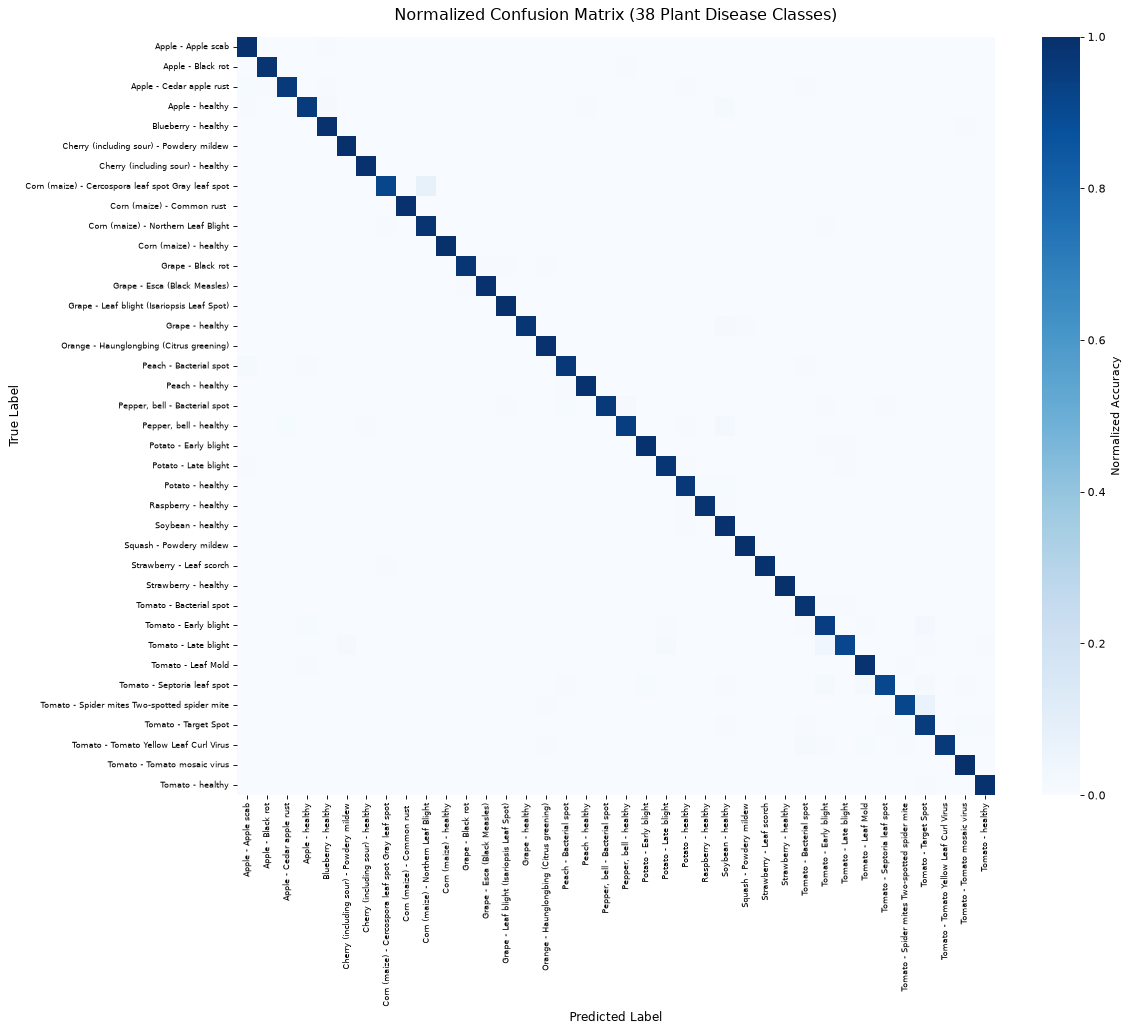


Confusion matrix saved successfully!

Top 10 Misclassified Disease Pairs (True -> Predicted):
                                        True Class                     Predicted Class  Error Count  Error Rate (%)
Corn (maize) - Cercospora leaf spot Gray leaf spot Corn (maize) - Northern Leaf Blight           33        8.048780
     Tomato - Spider mites Two-spotted spider mite                Tomato - Target Spot           28        6.436782
                              Tomato - Late blight               Tomato - Early blight           18        3.887689
                            Pepper, bell - healthy                   Soybean - healthy           13        2.615694
                             Tomato - Early blight                Tomato - Target Spot           10        2.083333
                              Tomato - Late blight                Potato - Late blight            9        1.943844
                                   Apple - healthy                   Soybean - healthy       

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
from sklearn.metrics import confusion_matrix

# 1. Calculate confusion matrices
num_classes = len(display_class_names)
labels = np.arange(num_classes)

cm_raw = confusion_matrix(
    all_targets,
    all_preds,
    labels=labels
)

# Row-normalized confusion matrix
row_totals = cm_raw.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm_raw,
    row_totals,
    out=np.zeros_like(cm_raw, dtype=float),
    where=row_totals != 0
)

print("Confusion matrix calculated successfully!")

# 2. Create a lightweight heatmap
fig, ax = plt.subplots(figsize=(15, 13), dpi=80)

sns.heatmap(
    cm_normalized,
    annot=False,
    cmap="Blues",
    xticklabels=display_class_names,
    yticklabels=display_class_names,
    cbar_kws={"label": "Normalized Accuracy"},
    ax=ax
)

ax.set_title(
    "Normalized Confusion Matrix (38 Plant Disease Classes)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.tick_params(axis="y", labelrotation=0, labelsize=7)

fig.tight_layout()

# 3. Save visualization before displaying
os.makedirs("saved_results", exist_ok=True)

fig.savefig(
    "saved_results/confusion_matrix.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nConfusion matrix saved successfully!")

# 4. Find the top 10 misclassified pairs
misclassifications = []

for i in range(num_classes):
    for j in range(num_classes):

        if i != j and cm_raw[i, j] > 0:

            error_rate = cm_normalized[i, j] * 100

            misclassifications.append((
                display_class_names[i],
                display_class_names[j],
                cm_raw[i, j],
                error_rate
            ))

# Sort by number of errors
misclassifications.sort(
    key=lambda x: x[2],
    reverse=True
)

# 5. Display top 10 errors
df_misclass = pd.DataFrame(
    misclassifications[:10],
    columns=[
        "True Class",
        "Predicted Class",
        "Error Count",
        "Error Rate (%)"
    ]
)

print("\nTop 10 Misclassified Disease Pairs (True -> Predicted):")

if not df_misclass.empty:
    print(df_misclass.to_string(index=False))
else:
    print("No misclassifications found!")
